# Model III
## Rozpoznawanie instrumentów za pomocą konwolucji (ResNet18)

### Biblioteki

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score
)

from model import Resnet
from trening import get_device, train_model
from przygotowanie_danych import (
    INSTRUMENTS,
    create_datasets,
    create_loaders
)

In [3]:
epochs = 100
patience = 10
batch_size = 64
learning_rate = 0.00001

dropout = 0.5

threshold = 0.8

expression = f"Resnet_batch{batch_size}_lr{learning_rate}_dr{dropout}"
weights_filename = f"weights_{expression}.pth"

In [4]:
train_dataset, val_dataset, test_dataset = create_datasets()

train_loader, val_loader, test_loader = create_loaders(train_dataset, val_dataset, test_dataset, batch_size=batch_size)

In [5]:
device = get_device()
print(device)

model = Resnet(dropout=dropout).to(device)

criterion = nn.MultiLabelSoftMarginLoss()

optimizer = optim.Adam(model.parameters(), lr=learning_rate)

cuda


In [6]:
X, y = next(iter(train_loader))

print("Wejście do ResNet:", X.shape)
print("Etykiety:", y.shape)
print("Warstwa wejściowa:", model.model.conv1)
print("Wyjście modelu:", model(X.to(device)).shape)

Wejście do ResNet: torch.Size([64, 1, 128, 346])
Etykiety: torch.Size([64, 7])
Warstwa wejściowa: Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
Wyjście modelu: torch.Size([64, 7])


In [7]:
start_time = time.perf_counter()

model, history, best_epoch, best_val_loss = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    epochs=epochs,
    patience=patience,
    model_name= str(weights_filename)
)

training_time = time.perf_counter() - start_time

print(f"Czas treningu: {training_time / 60:.2f} min")

Epoka 1/100 | Train loss: 0.6370 | Val loss: 0.4984
Epoka 2/100 | Train loss: 0.4922 | Val loss: 0.4217
Epoka 3/100 | Train loss: 0.4260 | Val loss: 0.3794
Epoka 4/100 | Train loss: 0.3799 | Val loss: 0.3479
Epoka 5/100 | Train loss: 0.3451 | Val loss: 0.3194
Epoka 6/100 | Train loss: 0.3126 | Val loss: 0.3033
Epoka 7/100 | Train loss: 0.2851 | Val loss: 0.2819
Epoka 8/100 | Train loss: 0.2615 | Val loss: 0.2687
Epoka 9/100 | Train loss: 0.2408 | Val loss: 0.2525
Epoka 10/100 | Train loss: 0.2227 | Val loss: 0.2432
Epoka 11/100 | Train loss: 0.2056 | Val loss: 0.2346
Epoka 12/100 | Train loss: 0.1920 | Val loss: 0.2285
Epoka 13/100 | Train loss: 0.1744 | Val loss: 0.2200
Epoka 14/100 | Train loss: 0.1626 | Val loss: 0.2198
Epoka 15/100 | Train loss: 0.1497 | Val loss: 0.2123
Epoka 16/100 | Train loss: 0.1393 | Val loss: 0.2050
Epoka 17/100 | Train loss: 0.1297 | Val loss: 0.2005
Epoka 18/100 | Train loss: 0.1185 | Val loss: 0.1967
Epoka 19/100 | Train loss: 0.1114 | Val loss: 0.1943
Ep

In [8]:
instrument_names = list(INSTRUMENTS.values())

model.eval()

with torch.no_grad():
    for X, y in test_loader:
        X = X.to(device)

        logits = model(X)
        probabilities = torch.sigmoid(logits).cpu().numpy()
        predictions = (probabilities >= threshold).astype(int)
        true_labels = y.cpu().numpy().astype(int)

        print("Prawdopodobieństwa:")
        display(pd.DataFrame(probabilities, columns=instrument_names).round(3))
        
        print("Przewidywane etykiety:")
        display(pd.DataFrame(predictions, columns=instrument_names))
        
        print("Prawdziwe etykiety:")
        display(pd.DataFrame(true_labels, columns=instrument_names))

        break

Prawdopodobieństwa:


,Gitara akustyczna,Saksofon altowy,Fortepian,Perkusja,Gitara basowa,Flet,Sekcja smyczkowa
0,0.992,0.938,0.039,0.003,0.999,0.011,0.996
1,0.714,0.052,0.993,0.997,0.995,0.959,0.004
2,0.984,0.026,0.767,0.019,0.017,0.184,1.000
3,0.998,0.994,0.932,0.004,0.974,0.001,0.999
4,0.001,0.998,0.775,0.008,0.997,0.003,0.028
...,...,...,...,...,...,...,...
59,0.987,0.007,0.994,0.004,0.992,0.616,1.000
60,0.449,0.998,0.836,0.999,0.245,0.005,0.008
61,0.007,0.074,0.003,0.014,0.004,0.949,0.382
62,0.006,0.014,0.069,0.997,0.099,0.038,0.960


Przewidywane etykiety:


,Gitara akustyczna,Saksofon altowy,Fortepian,Perkusja,Gitara basowa,Flet,Sekcja smyczkowa
0,1,1,0,0,1,0,1
1,0,0,1,1,1,1,0
2,1,0,0,0,0,0,1
3,1,1,1,0,1,0,1
4,0,1,0,0,1,0,0
...,...,...,...,...,...,...,...
59,1,0,1,0,1,0,1
60,0,1,1,1,0,0,0
61,0,0,0,0,0,1,0
62,0,0,0,1,0,0,1


Prawdziwe etykiety:


,Gitara akustyczna,Saksofon altowy,Fortepian,Perkusja,Gitara basowa,Flet,Sekcja smyczkowa
0,1,1,0,0,1,0,1
1,1,0,1,1,1,1,0
2,1,0,1,0,0,1,1
3,1,1,1,0,1,0,1
4,0,1,1,0,1,0,0
...,...,...,...,...,...,...,...
59,1,0,1,0,1,1,1
60,1,1,0,1,0,0,0
61,0,1,0,0,0,1,0
62,0,0,0,1,0,0,1


In [27]:
import torch

model.eval()

train_loss = 0.0
val_loss = 0.0

with torch.no_grad():
    for X, y in train_loader:
        X = X.to(device)
        y = y.to(device)

        logits = model(X)
        loss = criterion(logits, y)

        train_loss += loss.item() * X.size(0)

    for X, y in val_loader:
        X = X.to(device)
        y = y.to(device)

        logits = model(X)
        loss = criterion(logits, y)

        val_loss += loss.item() * X.size(0)

train_loss /= len(train_loader.dataset)
val_loss /= len(val_loader.dataset)

print(f"Train Loss: {train_loss:.4f}")
print(f"Validation Loss: {val_loss:.4f}")

Train Loss: 0.0139
Validation Loss: 0.1740


Best Micro-F1: 0.9324 | Threshold: 0.4228
Best Macro-F1: 0.9307 | Threshold: 0.4223


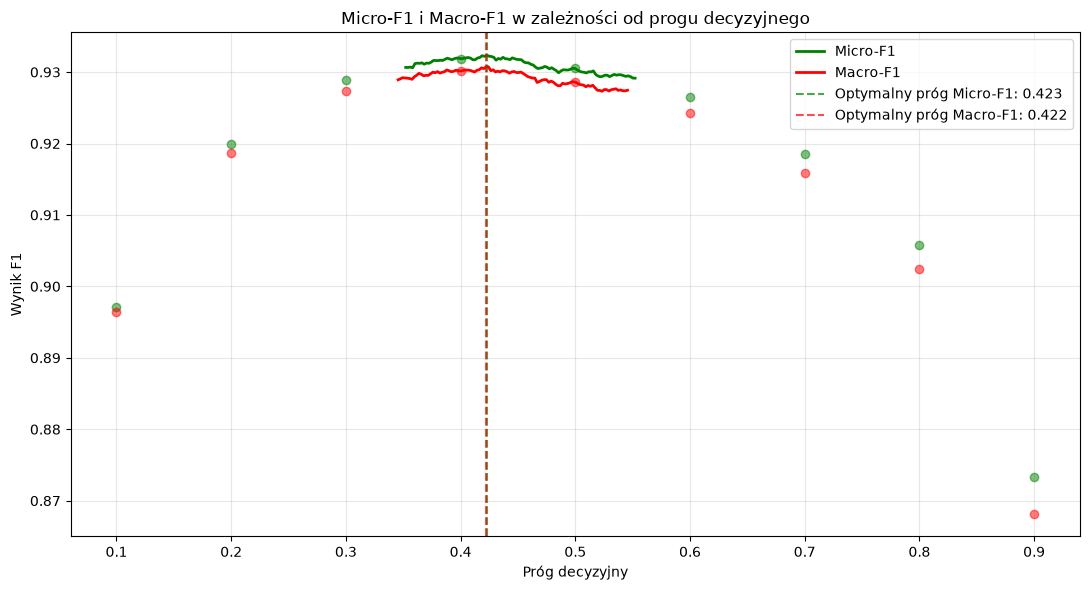

In [ ]:
model.eval()

all_logits = []
all_labels = []

with torch.no_grad():
    for X, y in val_loader:
        X = X.to(device)
        y = y.to(device)

        logits = model(X)

        all_logits.append(torch.sigmoid(logits).cpu().numpy())
        all_labels.append(y.cpu().numpy())

all_probabilities = np.concatenate(all_logits, axis=0)
all_labels = np.concatenate(all_labels, axis=0)


def calculate_f1(threshold):
    predictions = (all_probabilities >= threshold).astype(float)

    micro = f1_score(
        all_labels,
        predictions,
        average="micro",
        zero_division=0
    )

    macro = f1_score(
        all_labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return micro, macro


thresholds_coarse = np.linspace(0.1, 0.9, 9)

results_coarse = [
    calculate_f1(t) for t in thresholds_coarse
]

micro_coarse = np.array([r[0] for r in results_coarse])
macro_coarse = np.array([r[1] for r in results_coarse])


def estimate_maximum(thresholds, scores):
    a, b, c = np.polyfit(thresholds, scores, 2)

    if a < 0:
        estimated_threshold = -b / (2 * a)
    else:
        estimated_threshold = thresholds[np.argmax(scores)]

    return np.clip(estimated_threshold, 0.001, 0.999)


estimated_micro = estimate_maximum(thresholds_coarse, micro_coarse)
estimated_macro = estimate_maximum(thresholds_coarse, macro_coarse)

thresholds_micro = np.linspace(
    max(0.001, estimated_micro - 0.1),
    min(0.999, estimated_micro + 0.1),
    100
)

thresholds_macro = np.linspace(
    max(0.001, estimated_macro - 0.1),
    min(0.999, estimated_macro + 0.1),
    100
)

micro_fine = np.array([
    calculate_f1(t)[0] for t in thresholds_micro
])

macro_fine = np.array([
    calculate_f1(t)[1] for t in thresholds_macro
])

best_micro_idx = np.argmax(micro_fine)
best_macro_idx = np.argmax(macro_fine)

best_micro_threshold = thresholds_micro[best_micro_idx]
best_macro_threshold = thresholds_macro[best_macro_idx]

best_micro_f1 = micro_fine[best_micro_idx]
best_macro_f1 = macro_fine[best_macro_idx]

print(f"Best Micro-F1: {best_micro_f1:.4f} | Threshold: {best_micro_threshold:.4f}")
print(f"Best Macro-F1: {best_macro_f1:.4f} | Threshold: {best_macro_threshold:.4f}")

plt.figure(figsize=(11, 6))

plt.plot(
    thresholds_coarse,
    micro_coarse,
    "o",
    color="green",
    alpha=0.5
)

plt.plot(
    thresholds_coarse,
    macro_coarse,
    "o",
    color="red",
    alpha=0.5
)

plt.plot(
    thresholds_micro,
    micro_fine,
    color="green",
    linewidth=2,
    label="Micro-F1"
)

plt.plot(
    thresholds_macro,
    macro_fine,
    color="red",
    linewidth=2,
    label="Macro-F1"
)

plt.axvline(
    best_micro_threshold,
    color="green",
    linestyle="--",
    alpha=0.7,
    label=f"Optymalny próg Micro-F1: {best_micro_threshold:.3f}"
)

plt.axvline(
    best_macro_threshold,
    color="red",
    linestyle="--",
    alpha=0.7,
    label=f"Optymalny próg Macro-F1: {best_macro_threshold:.3f}"
)

plt.xlabel("Próg decyzyjny")
plt.ylabel("Wynik F1")
plt.title("Micro-F1 i Macro-F1 w zależności od progu decyzyjnego")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
results_dir = Path("wyniki")
results_dir.mkdir(exist_ok=True)

results_file = results_dir / f"porownanie_eksperymentow_{expression}.csv"

experiment = pd.DataFrame([{
    "Learning_ID" : expression,
    "Model": "Resnet18",
    "Batch size": batch_size,
    "Learning rate": learning_rate,
    "Dropout": dropout,
    "Threshold": threshold,
    "Best epoch": best_epoch,
    "Best val loss": best_val_loss,
    "Micro-F1": f1_micro,
    "Macro-F1": f1_macro,
    "Training time [min]": training_time / 60
}])

if results_file.exists():
    experiment.to_csv(
        results_file,
        mode="a",
        header=False,
        index=False
    )
else:
    experiment.to_csv(results_file, index=False)

experiment

,Learning_ID,Model,Batch size,Learning rate,Dropout,Threshold,Best epoch,Best val loss,Micro-F1,Macro-F1,Training time [min]
0,Resnet_batch64_lr1e-05_dr0.5,Resnet18,64,0.00001,0.5,0.8,40,0.174025,0.905744,0.902408,27.024795


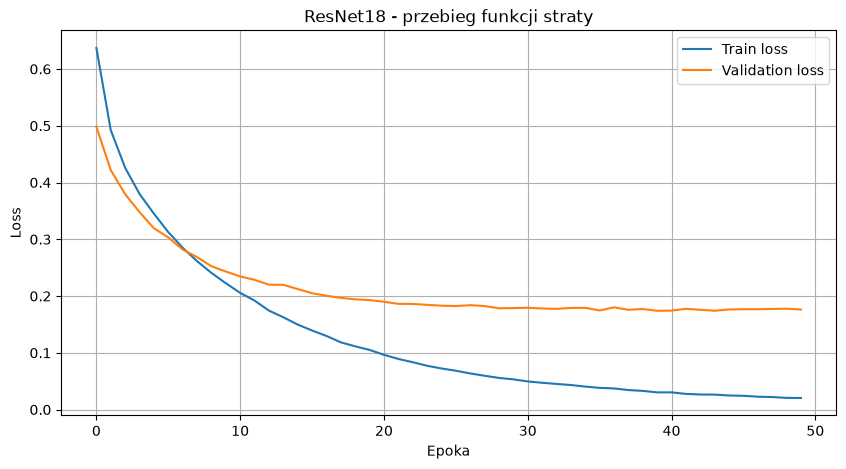

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(history["train_loss"], label="Train loss")
plt.plot(history["val_loss"], label="Validation loss")

plt.xlabel("Epoka")
plt.ylabel("Loss")
plt.title("ResNet18 - przebieg funkcji straty")

plt.legend()
plt.grid()
plt.show()

In [12]:
f1_per_instrument = f1_score(
    all_labels,
    all_predictions,
    average=None,
    zero_division=0
)

precision_per_instrument = precision_score(
    all_labels,
    all_predictions,
    average=None,
    zero_division=0
)

recall_per_instrument = recall_score(
    all_labels,
    all_predictions,
    average=None,
    zero_division=0
)

metrics_df = pd.DataFrame({
    "Instrument": instrument_names,
    "Precision": precision_per_instrument,
    "Recall": recall_per_instrument,
    "F1-score": f1_per_instrument
})

metrics_df

,Instrument,Precision,Recall,F1-score
0,Gitara akustyczna,0.974777,0.811111,0.885445
1,Saksofon altowy,0.959860,0.771388,0.855365
2,Fortepian,0.958457,0.813602,0.880109
3,Perkusja,0.998767,0.970060,0.984204
4,Gitara basowa,0.976096,0.884477,0.928030
5,Flet,0.939900,0.789621,0.858232
6,Sekcja smyczkowa,0.983471,0.873929,0.925470


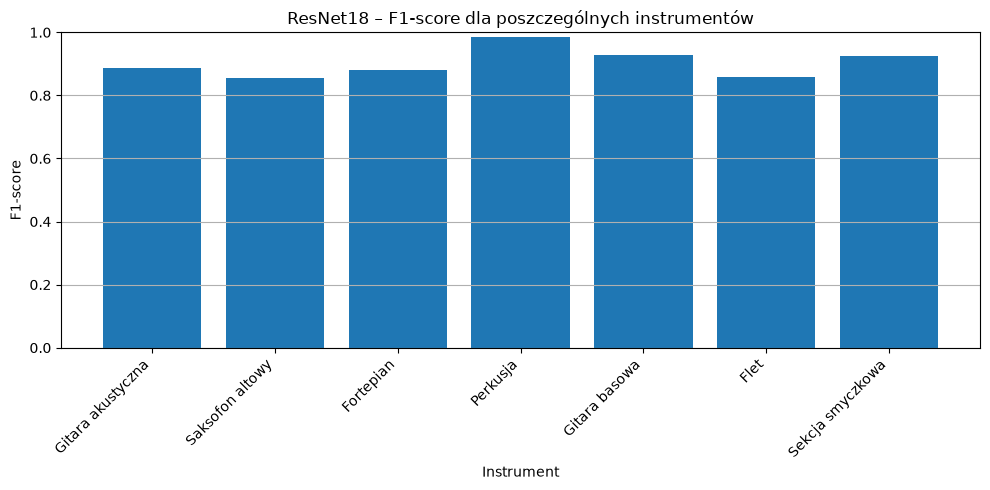

In [13]:
plt.figure(figsize=(10, 5))

plt.bar(instrument_names, f1_per_instrument)

plt.xlabel("Instrument")
plt.ylabel("F1-score")
plt.title("ResNet18 – F1-score dla poszczególnych instrumentów")

plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.grid(axis="y")

plt.tight_layout()
plt.show()